In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xobjects as xo
import xtrack as xt
import xpart as xp
import sys
import xplt
import scipy.constants as sc
sys.path.append('/mnt/c/muco/code')
from rcsparameters.geometry.geometry import Geometry, load_file
from rcsparameters.geometry.cell import Cell
from generate_fodo import fodo, plot_twiss, apert_1b_optics, apert_2b_optics,size_beam_diam_hor, plot_path_diff,size_beam_diam_vert,vert_apert
# from ramping_module import ramping
# from track_function import track
import json

plt.rc('axes', labelsize=12)     # fontsize of the x and y labels
plt.rc('xtick', labelsize=11)    # fontsize of the tick labels
plt.rc('ytick', labelsize=11)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize

/mnt/c/muco/test_venv/lib/python3.11/site-packages/numpy/_core/getlimits.py:545: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


Define geometry

In [2]:
file_input='/mnt/c/muco/code/class_geometry/parameter_files/para_RCS_FE.txt'
kw_geo=load_file(file_input)
kw_geo['pattern']=['BSC','BNC','BSC', 'BSC','BNC','BSC'] 
kw_geo['nb_bloc']=2
print(kw_geo)
default_para_RCS1={
        'n_sigma':6, #Nb of sigma of beam size that the QP aperture must fit
        'sigma_delta':5e-3, #Max dispersion in energy of the beam
        'emitt_n':25e-6, #Normalized emittance
        'n_cav':3000, #Total number of cavity : 700, 380, 540, 3000 
        'l_cav':1.2474, #Length of 1 cavity
        'mu':np.pi/2, #Phase advance per cell
        'apert_min':30e-3, #Min aperture size (diam) to be taken for QP
        'dx':10e-3, #Extra radius length to be taken to fit vacuum chambers
        'Bpole':1, #Max field on QP pole
    }
rcs = Cell(file_input_geo=kw_geo,file_input_opt=default_para_RCS1)
print(rcs.nb_cell_arc)
rcs.nb_cell_arc=9
rcs.reinit_cell()
time=0
n_slice=0
L_sxt=1
n_turn_rcs=55
option='var_ref'

Load json file /mnt/c/muco/code/class_geometry/parameter_files/para_RCS_FE.txt
{'type': 'hybrid', 'circumference': 35000, 'injection_energy': 1500000000000.0, 'extraction_energy': 5000000000000.0, 'length_short_insertion': 2.5, 'dipole_spacing': 0.4, 'nb_RF_section': 24, 'nb_arc': 26, 'nb_cell_arc': 19, 'dipoles': {'BNC': [1.8, 'linear'], 'BSC': 16.0}, 'filling_ratio': 0.9, 'filling_ratio_RF': 0.4, 'pattern': ['BSC', 'BNC', 'BSC', 'BSC', 'BNC', 'BSC'], 'nb_bloc': 2}
2bloc
geo
10.0
2bloc


/mnt/c/muco/mhega/rcsparameters/rcsparameters/geometry/geometry.py:299: UserWarning: Number of cells per arc was optimised from 19 to 10
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)


Equivalent FODO cell

Repetition found in `element_names` -> renaming


Extra per quad: 1.7122797773520944
Total insertion length 134.6153846153846


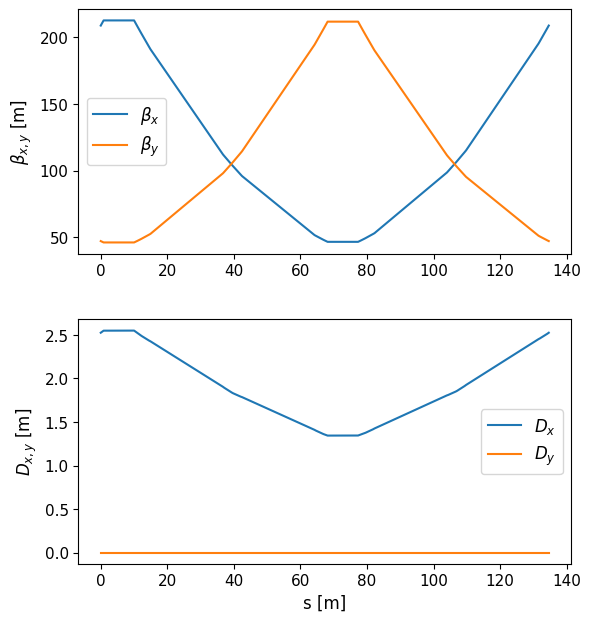

In [3]:
FODO_el, FODO_names, arc_el, arc_names=fodo(RCS=rcs, n_turn_rcs=n_turn_rcs, length_sxt=L_sxt, time_frac=time, option=option, n_slice=n_slice)

line_FODO=xt.Line(elements=FODO_el, element_names=FODO_names)
line_FODO.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, 
                                      q0=1, mass0=xp.MUON_MASS_EV)
tw_FODO=line_FODO.twiss(method='4d')
tw_init_FODO = tw_FODO.get_twiss_init('quad_d')
plot_twiss(tw_FODO)

In [4]:
line_tr=xt.Line(elements=arc_el, element_names=arc_names)
line_tr.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, 
                                    q0=1, mass0=xp.MUON_MASS_EV)

Repetition found in `element_names` -> renaming


Working on a half-arc to match the dispersion suppressor. Working in transfer line mode 

In [5]:
line_tr.element_names

['quad_d',
 'sxt_d',
 'drift_ext',
 'drift_dd',
 'BSC',
 'drift_dd_1',
 'BNC',
 'drift_dd_2',
 'BSC_1',
 'drift_dd_3',
 'BSC_2',
 'drift_dd_4',
 'BNC_1',
 'drift_dd_5',
 'BSC_3',
 'drift_dd_6',
 'drift_ext_1',
 'quad_f',
 'sxt_f',
 'drift_ext_2',
 'drift_dd_7',
 'BSC_4',
 'drift_dd_8',
 'BNC_2',
 'drift_dd_9',
 'BSC_5',
 'drift_dd_10',
 'BSC_6',
 'drift_dd_11',
 'BNC_3',
 'drift_dd_12',
 'BSC_7',
 'drift_dd_13',
 'drift_ext_3',
 'quad_d_1',
 'sxt_d_1',
 'drift_ext_4',
 'drift_dd_14',
 'BSC_8',
 'drift_dd_15',
 'BNC_4',
 'drift_dd_16',
 'BSC_9',
 'drift_dd_17',
 'BSC_10',
 'drift_dd_18',
 'BNC_5',
 'drift_dd_19',
 'BSC_11',
 'drift_dd_20',
 'drift_ext_5',
 'quad_f_1',
 'sxt_f_1',
 'drift_ext_6',
 'drift_dd_21',
 'BSC_12',
 'drift_dd_22',
 'BNC_6',
 'drift_dd_23',
 'BSC_13',
 'drift_dd_24',
 'BSC_14',
 'drift_dd_25',
 'BNC_7',
 'drift_dd_26',
 'BSC_15',
 'drift_dd_27',
 'drift_ext_7',
 'quad_d_2',
 'sxt_d_2',
 'drift_ext_8',
 'drift_dd_28',
 'BSC_16',
 'drift_dd_29',
 'BNC_8',
 'drift_dd

In [6]:
line_tr.vars['kf1'] = line_tr['quad_f'].k1
line_tr.vars['kd1'] = line_tr['quad_d'].k1
line_tr.vars['kf2'] = line_tr['quad_f'].k1
line_tr.vars['kd2'] = line_tr['quad_d'].k1
line_tr.vars['kf3'] = line_tr['quad_f'].k1
line_tr.vars['kd3'] = line_tr['quad_d'].k1

line_tr.element_refs['quad_f_4'].k1 = line_tr.vars['kf1']
line_tr.element_refs['quad_f_3'].k1 = line_tr.vars['kf2']
# line_tr.element_refs['quad_f_2'].k1 = line_tr.vars['kf3']

line_tr.element_refs['quad_d_4'].k1 = line_tr.vars['kd1']
line_tr.element_refs['quad_d_3'].k1 = line_tr.vars['kd2']
# line_tr.element_refs['quad_d_2'].k1 = line_tr.vars['kd3']

match_tr=line_tr.match(
            start='quad_d',
            end='marker_end', 
            init=tw_init_FODO,
            vary=xt.VaryList(['kf1','kd1','kd2','kf2'], #,'kf3'
                            step=1e-8,
                            tag='quad'),
            targets=[xt.TargetSet(dx=0,dpx=0,alfx=0,alfy=0, at='marker_end',tol=1e-9)], 
            method='4d',
            solve=True
            )
# match_tr.step(100)
print('RESULTS FROM TR MATCHING')
match_tr.target_status()
match_tr.vary_status()

Matching: model call n. 99               

RESULTS FROM TR MATCHING
Target status:                            
id state tag tol_met      residue  current_val target_val description                                 
 0 ON           True   2.5682e-10   2.5682e-10          0 ('alfx', 'marker_end'), val=0, tol=1e-09 ...
 1 ON           True -3.19529e-13 -3.19529e-13          0 ('alfy', 'marker_end'), val=0, tol=1e-09 ...
 2 ON           True -1.94168e-10 -1.94168e-10          0 ('dx', 'marker_end'), val=0, tol=1e-09,  ...
 3 ON           True  2.35638e-11  2.35638e-11          0 ('dpx', 'marker_end'), val=0, tol=1e-09, ...
Vary status:                 
id state tag  met name lower_limit current_val upper_limit val_at_iter_0  step weight
 0 ON    quad OK  kf1  None         0.00219507 None           0.00231151 1e-08      1
 1 ON    quad OK  kd1  None        -0.00220746 None          -0.00231151 1e-08      1
 2 ON    quad OK  kd2  None        -0.00205712 None          -0.00231151 1e-08      1


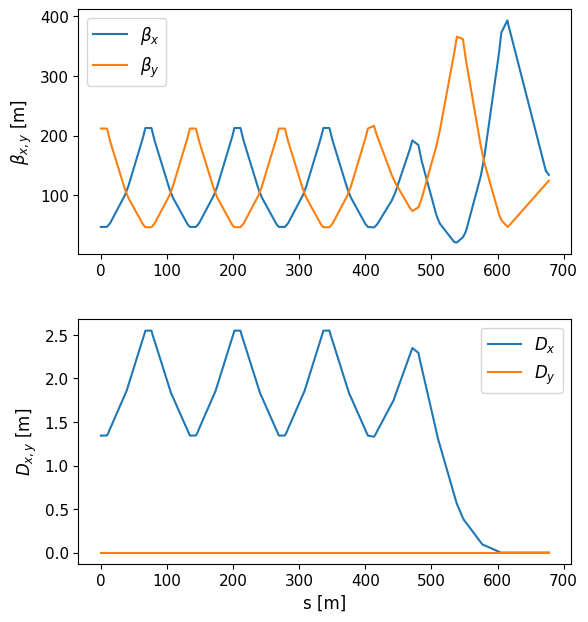

In [7]:
tw_tr=line_tr.twiss(method='4d',  
            start='quad_d',
            end='marker_end', 
            init=tw_init_FODO)
plot_twiss(tw_tr)
tw_init_tr = tw_tr.get_twiss_init('marker_end')

Creating the full arc and checking the closure of the RCS and total circumference

Repetition found in `element_names` -> renaming


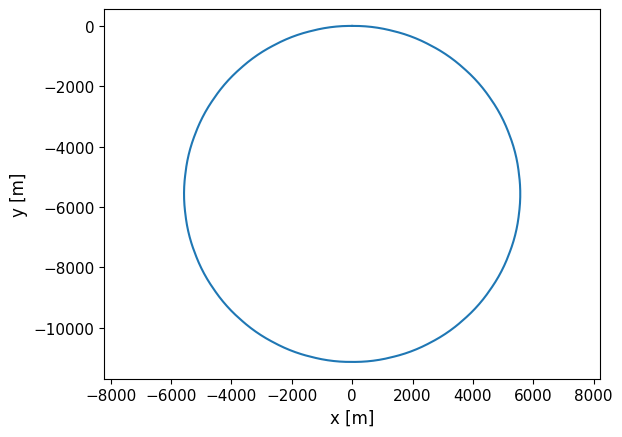

SURVEY RESULTS
X final 1.808304783358862e-10
Z final 4.2728487414933625e-11
s total 34974.21876883914
Circumference 35000
Theta/2pi final -1.0000000000000007


In [8]:
tr=arc_el[2:]
tot_arc_el=tr[::-1]+arc_el
tr_name=arc_names[2:]
tot_arc_names=tr_name[::-1]+arc_names
line_tot=xt.Line(elements=tot_arc_el*rcs.nb_arc, element_names=tot_arc_names*rcs.nb_arc)
line_tot.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, q0=1, mass0=xp.MUON_MASS_EV)
line_tot.build_tracker()
survey=line_tot.survey()
plt.figure()
plt.plot(survey['Z'], survey['X'])
plt.axis('equal')
# for i, el in enumerate(line.element_names):
#     if 'dip' in el:
#         plt.axvline(x=survey['Z'][i], color='grey', linestyle='--')
#     elif 'quad' in el:
#         plt.axvline(x=survey['Z'][i], color='red', linestyle='--')
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.show()
print('SURVEY RESULTS')
print('X final', survey['X'][-1])
print('Z final', survey['Z'][-1])
print('s total', survey['s'][-1])
print('Circumference', rcs.circumference)
print('Theta/2pi final', survey['theta'][-1]/np.pi/2)

In [9]:
print(tr_name)
print(arc_names)

['drift_ext', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'drift_ext', 'quad_f', 'sxt_f', 'drift_ext', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'drift_ext', 'quad_d', 'sxt_d', 'drift_ext', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'drift_ext', 'quad_f', 'sxt_f', 'drift_ext', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'drift_ext', 'quad_d', 'sxt_d', 'drift_ext', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'drift_ext', 'quad_f', 'sxt_f', 'drift_ext', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'drif

Creating the line of an arc

In [10]:
line_ds=xt.Line(elements=tot_arc_el, element_names=tot_arc_names)
line_ds.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, q0=1, mass0=xp.MUON_MASS_EV)
tab_ds=line_ds.get_table()

Repetition found in `element_names` -> renaming


Matching the dispersion suppressor on the arc from the transfer line results

In [11]:
line_ds.element_names

['marker_end',
 'quad_d_half',
 'RF_acc',
 'cavity',
 'drift_ins',
 'drift_ext',
 'quad_f',
 'drift_ext_1',
 'drift_dd',
 'BSC',
 'drift_dd_1',
 'BNC',
 'drift_dd_2',
 'BSC_1',
 'drift_dd_3',
 'BSC_2',
 'drift_dd_4',
 'BNC_1',
 'drift_dd_5',
 'BSC_3',
 'drift_dd_6',
 'drift_ext_2',
 'sxt_d',
 'quad_d',
 'drift_ext_3',
 'drift_dd_7',
 'BSC_4',
 'drift_dd_8',
 'BNC_2',
 'drift_dd_9',
 'BSC_5',
 'drift_dd_10',
 'BSC_6',
 'drift_dd_11',
 'BNC_3',
 'drift_dd_12',
 'BSC_7',
 'drift_dd_13',
 'drift_ext_4',
 'sxt_f',
 'quad_f_1',
 'drift_ext_5',
 'drift_dd_14',
 'BSC_8',
 'drift_dd_15',
 'BNC_4',
 'drift_dd_16',
 'BSC_9',
 'drift_dd_17',
 'BSC_10',
 'drift_dd_18',
 'BNC_5',
 'drift_dd_19',
 'BSC_11',
 'drift_dd_20',
 'drift_ext_6',
 'sxt_d_1',
 'quad_d_1',
 'drift_ext_7',
 'drift_dd_21',
 'BSC_12',
 'drift_dd_22',
 'BNC_6',
 'drift_dd_23',
 'BSC_13',
 'drift_dd_24',
 'BSC_14',
 'drift_dd_25',
 'BNC_7',
 'drift_dd_26',
 'BSC_15',
 'drift_dd_27',
 'drift_ext_8',
 'sxt_f_1',
 'quad_f_2',
 'drift_

In [12]:
tw_ds=line_ds.twiss(method='6d', matrix_stability_tol=0.05)

In [13]:
line_ds.vars['kf1'] = line_tr['quad_f_4'].k1
line_ds.vars['kd1'] = line_tr['quad_d_4'].k1
line_ds.vars['kf2'] = line_tr['quad_f_3'].k1
line_ds.vars['kd2'] = line_tr['quad_d_3'].k1
line_ds.vars['kf3'] = line_tr['quad_f_2'].k1
# line_ds.vars['kd3'] = line_tr['quad_d_2'].k1


line_ds.element_refs['quad_f_9'].k1 = line_ds.vars['kf1']
# line_ds.element_refs['quad_f_1'].k1 = line_ds.vars['kf1']
line_ds.element_refs['quad_f_8'].k1 = line_ds.vars['kf2']
# line_ds.element_refs['quad_f_2'].k1 = line_ds.vars['kf2']
line_ds.element_refs['quad_f_7'].k1 = line_ds.vars['kf3']
# line_ds.element_refs['quad_f_3'].k1 = line_ds.vars['kf3']

line_ds.element_refs['quad_d_8'].k1 = line_ds.vars['kd1']
# line_ds.element_refs['quad_d'].k1 = line_ds.vars['kd1']
line_ds.element_refs['quad_d_7'].k1 = line_ds.vars['kd2']
# line_ds.element_refs['quad_d_6'].k1 = line_ds.vars['kd3']

match_ds=line_ds.match(
                vary=xt.VaryList(['kf1','kd1','kd2','kf2','kf3'], 
                                step=1e-8,
                                tag='quad'),
                targets=[
                    xt.TargetSet(dx=0, at='marker_end',tol=1e-9),
                    xt.TargetSet(qx=2.524, qy=2.254, tol=1e-9)
                        ],
                method='6d',
                matrix_stability_tol=0.05,
                solve=False
                )
match_ds.step(50)
print('RESULTS FROM DS MATCHING')
match_ds.target_status()
match_ds.vary_status()

tw_ds=line_ds.twiss(method='6d', matrix_stability_tol=0.05)

RESULTS FROM DS MATCHING28               
Target status:                           
id state tag tol_met      residue current_val target_val description                                 
 0 ON           True   3.5254e-10  3.5254e-10          0 ('dx', 'marker_end'), val=0, tol=1e-09,  ...
 1 ON           True -2.43767e-10       2.524      2.524 'qx', val=2.524, tol=1e-09, weight=10       
 2 ON           True  3.55271e-14       2.254      2.254 'qy', val=2.254, tol=1e-09, weight=10       
Vary status:                 
id state tag  met name lower_limit current_val upper_limit val_at_iter_0  step weight
 0 ON    quad OK  kf1  None         0.00224064 None           0.00219507 1e-08      1
 1 ON    quad OK  kd1  None        -0.00223925 None          -0.00220746 1e-08      1
 2 ON    quad OK  kd2  None        -0.00207491 None          -0.00205712 1e-08      1
 3 ON    quad OK  kf2  None         0.00283283 None           0.00280035 1e-08      1
 4 ON    quad OK  kf3  None         0.00233014 N

Matching: model call n. 12               

RESULTS FROM TR MATCHING
Target status:                           
id state tag    tol_met     residue current_val target_val description                             
 0 ON    chroma    True 9.89605e-07    0.192309   0.192308 'dqx', val=0.192308, tol=1e-06, weight=1
 1 ON    chroma    True 9.45841e-12    0.192308   0.192308 'dqy', val=0.192308, tol=1e-06, weight=1
Vary status:                 
id state tag met name lower_limit current_val upper_limit val_at_iter_0  step weight
 0 ON    sxt OK  sf   None          0.0122251 None            0.0113122 1e-06      1
 1 ON    sxt OK  sd   None         -0.0240391 None            0.0147055 1e-06      1


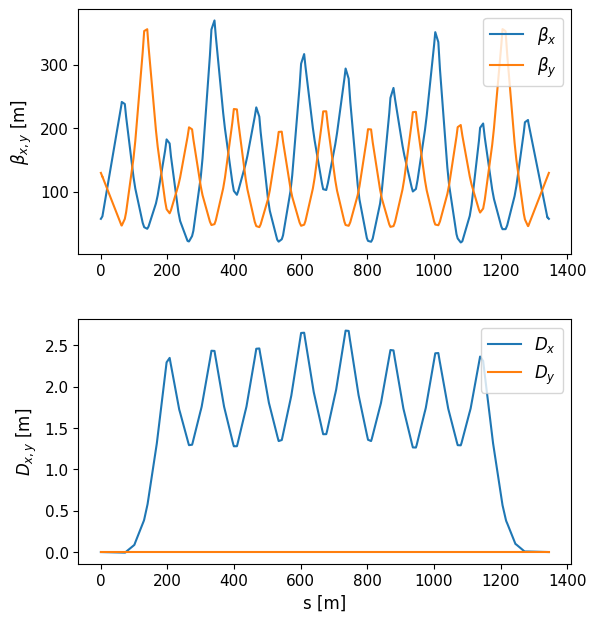

In [14]:
line_ds.vars['sf'] = line_ds['quad_f_1'].k1*line_ds['quad_f_1'].length/tw_ds['dx','quad_f_1']/line_ds['sxt_f'].length
line_ds.vars['sd'] = -line_ds['quad_d_1'].k1*line_ds['quad_d_1'].length/tw_ds['dx','quad_d_1']/line_ds['sxt_d'].length

for sxt in tab_ds.rows[tab_ds.element_type=='Sextupole'].name:
    if 'sxt_d' in sxt:
        line_ds.element_refs[sxt].k2 = line_ds.vars['sd']
    elif 'sxt_f' in sxt:
        line_ds.element_refs[sxt].k2 = line_ds.vars['sf']
    
chroma_goal=5/rcs.nb_arc

match_ds_chroma=line_ds.match(
                vary=xt.VaryList(['sf','sd'], 
                                step=1e-6,
                                tag='sxt'),
                targets=[
                    xt.TargetSet(dqx=chroma_goal, dqy=chroma_goal, tol=1e-6, tag='chroma')
                    ],
                method='6d',
                matrix_stability_tol=0.05,
                solve=True
                )
print('RESULTS FROM TR MATCHING')
match_ds_chroma.target_status()
match_ds_chroma.vary_status()

tw_ds=line_ds.twiss(method='6d', matrix_stability_tol=0.05)
plot_twiss(tw_ds)

Printing some global parameters: dipole lengths, dipole aperture, qp aperture, path length difference ....

In [15]:
tab=line_ds.get_table()
quad_k1=[]
sxt_k2=[]
for quad in tab.rows[tab.element_type == 'Quadrupole'].name:
    print(quad, line_ds[quad].k1)
    quad_k1.append(line_ds[quad].k1)
for sxt in tab.rows[tab.element_type == 'Sextupole'].name:
    print(sxt, line_ds[sxt].k2)
    sxt_k2.append(line_ds[sxt].k2)
print(max(np.absolute(quad_k1)), max(np.absolute(sxt_k2)))

quad_d_half -0.002311514676737489
quad_f 0.0022406411486529166
quad_d -0.0022392478280676763
quad_f_1 0.0028328259363826404
quad_d_1 -0.002074905074257184
quad_f_2 0.0023301378292219874
quad_d_2 -0.002311514676737489
quad_f_3 0.002311514676737489
quad_d_3 -0.002311514676737489
quad_f_4 0.002311514676737489
quad_d_4 -0.002311514676737489
quad_f_5 0.002311514676737489
quad_d_5 -0.002311514676737489
quad_f_6 0.002311514676737489
quad_d_6 -0.002311514676737489
quad_f_7 0.0023301378292219874
quad_d_7 -0.002074905074257184
quad_f_8 0.0028328259363826404
quad_d_8 -0.0022392478280676763
quad_f_9 0.0022406411486529166
quad_d_half_1 -0.002311514676737489
sxt_d -0.024039108374932595
sxt_f 0.012225136751826902
sxt_d_1 -0.024039108374932595
sxt_f_1 0.012225136751826902
sxt_d_2 -0.024039108374932595
sxt_f_2 0.012225136751826902
sxt_d_3 -0.024039108374932595
sxt_f_3 0.012225136751826902
sxt_d_4 -0.024039108374932595
sxt_f_4 0.012225136751826902
sxt_d_5 -0.024039108374932595
sxt_f_5 0.0122251367518269

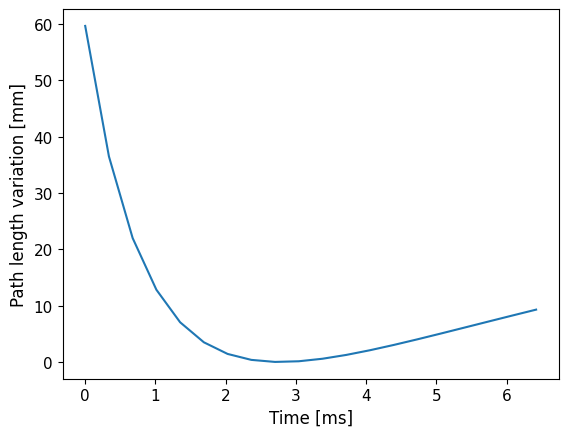

GLOBAL PARAMETER
C 35000
NB arc 26
Nb of cells per arc 9
Cell length 133.58034188034188
Longueur totale NC 20376.118030528596
Longueur totale SC 4257.153225041556
FF arc 0.893
Dipole FF 0.704
MCF 0.000287
Transition gamma 59.02
Qs 0.54
Qx 65.624
Qy 58.604
dqx 5.0
dqy 5.0
pattern ['BSC', 'BNC', 'BSC', 'BSC', 'BNC', 'BSC']
Max path length diff 59.7 mm
Relative path length diff 1.71 e-6
Traj excursion SC 18.0 mm
Hor apert SC 74.0 mm
Length SC 2.27 m
Traj excursion NC 130.0 mm
Hor apert NC 186.0 mm
Length NC 21.77 m
Horizontal beam size 36.5 mm
Vertical beam size 9.5 mm
Vertical aperture 29.5 mm
Length QP 9.16 m
QP Bpole for 50mm apert 1.18 T
Extra length QP 1.71 m
Length SXT 1.0 m
SXT Bpole for 50mm apert 0.13 T


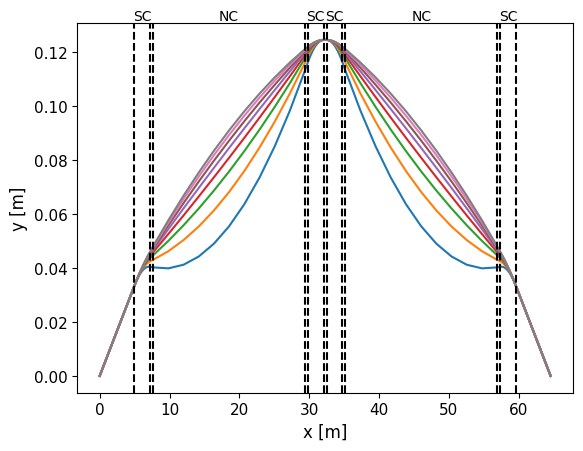

In [16]:
delta=5e-3
max_path_diff=plot_path_diff(rcs, n_turn_rcs)
hor_size_beam=size_beam_diam_hor(tw_ds, rcs, delta)
vert_size_beam=size_beam_diam_vert(tw_ds, rcs, delta)
apert_V=vert_apert(tw_ds, rcs, delta)
print('GLOBAL PARAMETER')
print('C', rcs.circumference)
print('NB arc', rcs.nb_arc)
print('Nb of cells per arc', rcs.nb_cell_arc)
print('Cell length', rcs.cell_length)
print('Longueur totale NC', rcs.dipole_families['BNC']['tot_length'])
if rcs.type == 'hybrid':
    print('Longueur totale SC', rcs.dipole_families['BSC']['tot_length'])
print('FF arc', np.round(rcs.filling_ratio,3))
print('Dipole FF', np.round(rcs.filling_ratio_dipole,3))
print('MCF', round(tw_ds['momentum_compaction_factor'], 6))
print('Transition gamma', round(1/np.sqrt(tw_ds['momentum_compaction_factor']), 2))

print('Qs', round(tw_ds['qs']*rcs.nb_arc, 3))
print('Qx', round(tw_ds['qx']*rcs.nb_arc, 3))
print('Qy', round(tw_ds['qy']*rcs.nb_arc, 3))
print('dqx', round(tw_ds['dqx']*rcs.nb_arc, 2))
print('dqy', round(tw_ds['dqy']*rcs.nb_arc, 2))
print('pattern', rcs.pattern)
if rcs.type == 'hybrid':
    print('Max path length diff', round(max_path_diff*1e3,1), 'mm')
    print('Relative path length diff', round(max_path_diff/rcs.circumference*1e6,2), 'e-6')
    print('Traj excursion SC', round(rcs.width_sc_opt*1e3,0), 'mm')
    print('Hor apert SC', round((rcs.width_sc_opt+hor_size_beam+2*rcs.dx_qp)*1e3,0), 'mm')
    # print('Apert SC', round(rcs.aperture_sc_opt*1e3,0), 'mm')
    print('Length SC', round(rcs.dipole_families['BSC']['length'],2), 'm')
    print('Traj excursion NC', round(rcs.width_nc_opt*1e3,0), 'mm')
    # print('Apert NC', round(rcs.aperture_nc_opt*1e3,0), 'mm')
    print('Hor apert NC', round((rcs.width_nc_opt+hor_size_beam+2*rcs.dx_qp)*1e3,0), 'mm')
print('Length NC', round(rcs.dipole_families['BNC']['length'],2), 'm')
print('Horizontal beam size', round(hor_size_beam*1e3,1), 'mm')
print('Vertical beam size', round(vert_size_beam*1e3,1), 'mm')
print('Vertical aperture', round(apert_V*1e3,1), 'mm')
print('Length QP', round(line_ds['quad_d'].length,2), 'm')
print('QP Bpole for 50mm apert', round(max(np.absolute(quad_k1))*rcs.ext_Brho*(25e-3),2), 'T')
print('Extra length QP', round(line_ds['drift_ext'].length*2,2), 'm')
print('Length SXT', round(line_ds['sxt_d'].length,2), 'm')
print('SXT Bpole for 50mm apert', round(max(np.absolute(sxt_k2))/2*rcs.ext_Brho*(25e-3)**2,2), 'T')

rcs.plot_traj()

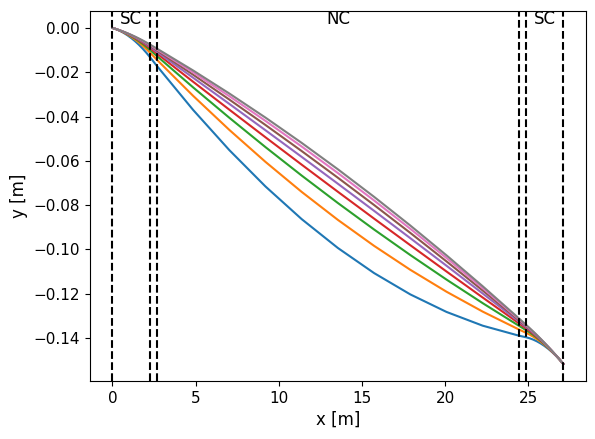

In [17]:
rcs.plot_2bloc_traj()

In [18]:
# line_ds.to_json('/mnt/c/muco/code/lattice/RCS4_DS_ext.json')
# para = {  "type": rcs.type,
#    "circumference": rcs.C,
#    "injection_energy": rcs.E_inj,
#    "extraction_energy": rcs.E_ext,
#    "length_short_insertion": rcs.LSSS,
#    "dipole_spacing": rcs.dipole_spacing,
#    "nb_RF_section": rcs.nb_RF_section,
#    "nb_arc": rcs.nb_arc,
#    "nb_cell_arc": rcs.nb_cell_arc,
#    "dipoles": rcs.dipoles,
#    "filling_ratio": rcs.filling_ratio,
#    "filling_ratio_RF": rcs.filling_ratio_RF,
#    "pattern": rcs.pattern
# }
# with open('para_RCS4_opt_2bloc.json', 'w') as file:
#     json.dump(para, file,indent=4)